# 學生學習與作業版｜任務 4：描述統計與視覺化

**姓名：**＿＿＿＿　**學號／組別：**＿＿＿＿　**完成日期：**＿＿＿＿

**學習目標：** 以描述統計、直方圖和盒鬚圖理解分布與離群值。

本單元與教師版「任務 4」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「4.2 直方圖」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 4.1 描述統計
**觀念說明：**count 是非缺失筆數，mean 是平均，50% 是中位數。極端值可能影響平均，不能只看單一統計量。


In [2]:
# describe 彙整筆數、平均、標準差、四分位數與最大最小值
display(df[["quiz_score", "sleep_hours", "screen_time_hours"]].describe())
print("總筆數：", len(df), "睡眠有效筆數：", df["sleep_hours"].count())
print("螢幕時間平均／中位數：", df["screen_time_hours"].mean(), df["screen_time_hours"].median())


,quiz_score,sleep_hours,screen_time_hours
count,60.000000,58.000000,60.000000
mean,78.800000,6.682759,4.946667
std,6.681114,0.822307,1.985239
min,63.000000,4.800000,1.800000
25%,75.000000,6.200000,3.600000
50%,80.000000,6.750000,4.700000
75%,82.250000,7.300000,5.625000
max,92.000000,9.100000,15.000000


總筆數： 60 睡眠有效筆數： 58
螢幕時間平均／中位數： 4.946666666666668 4.7


## 📝 學生作業 04-Q1｜AI 查詢與作答：統計量
**任務：**平均數與中位數如何受到極端值影響？以具體數字說明。

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：＿＿＿＿我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：＿＿＿＿資料分析中，平均數（Mean）與中位數（Median）都是用來衡量資料集中趨勢的指標，但兩者對「極端值（Outlier，又稱離群值）」的敏感度完全不同。
- 我的理解與具體例子：＿＿＿＿假設我們調查某間新創公司 7 位員工的年薪（單位：萬元）：

一般員工（6 位）：55, 60, 62, 65, 68, 70

創辦人兼執行長（1 位）：450

我們把這 7 筆資料由小到大排列：[55, 60, 62, 65, 68, 70, 450]
- 查證來源／方式及日期（無法查證請註明）：＿＿＿＿無法查證
- 我檢查或修正 AI 回答的地方：＿＿＿＿受眾與環境設定（已遵守）：設定為「Python 與資料分析初學者」，因此我只使用內建的 statistics 模組，沒有直接跳到較進階的 numpy 或 pandas，避免增加初學者的環境安裝門檻。


## 4.2 直方圖
橫軸是分數區間，縱軸為該區間人數。調整 bins 會改變切分方式，不會改變資料；比較不同圖前確認尺度與分箱。


## 💻 學生作業 04-P1｜Vibe Coding 程式填空
**對應教師版：**任務 4「4.2 直方圖」的示範程式。

**任務：**在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


<Figure size 700x400 with 0 Axes>

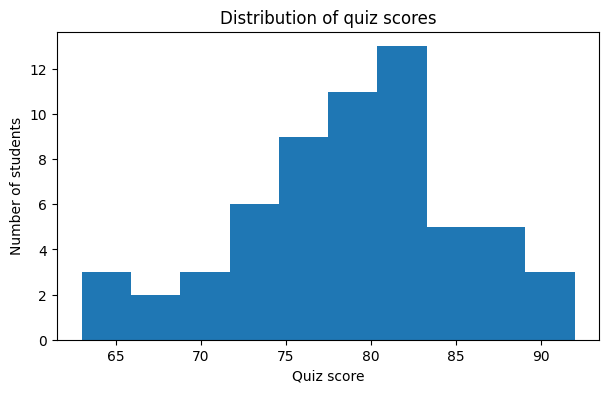

有效成績筆數： 60


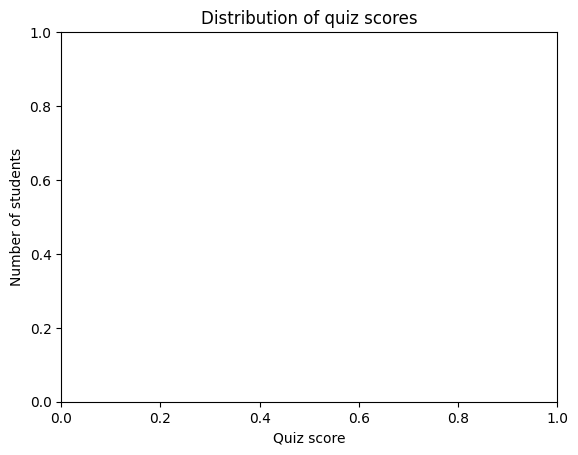

有效成績筆數： 60


In [6]:
# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))
# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))
# 選取 quiz_score 欄位並用 dropna() 暫時排除缺失值，接著以 bins=10 繪製直方圖（不修改原始 df）
plt.hist(df["quiz_score"].dropna(), bins=10)
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效成績筆數：", df["quiz_score"].count())  # TODO：以 quiz_score 的非缺失資料畫 bins=10 的直方圖
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效成績筆數：", df["quiz_score"].count())


### ✅ 作業 04-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [9]:
assert df["quiz_score"].notna().sum() == 60
print("請人工檢查上方直方圖的標題、軸及 10 個分箱。")


請人工檢查上方直方圖的標題、軸及 10 個分箱。


### ✍️ 作業 04-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：＿＿＿＿我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
- 我補上的程式在做什麼：＿＿＿＿# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))
# 選取 quiz_score 欄位並用 dropna() 暫時排除缺失值，接著以 bins=10 繪製直方圖（不修改原始 df）
plt.hist(df["quiz_score"].dropna(), bins=10)
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效成績筆數：", df["quiz_score"].count())
- 執行或驗證遇到的問題與修正：＿＿＿＿Colab 閒置過久自動斷線重啟，或是你只執行了這一格（Cell），忘記先執行上方匯入套件（import matplotlib.pyplot as plt、import pandas as pd）與讀取資料（df = ...）的儲存格。
- 檢查結果及我如何確認：＿＿＿＿圖表標題與座標軸是否正確保留


## 📝 學生作業 04-Q2｜AI 查詢與作答：圖形解讀
**任務：**直方圖 bins 改變時，為何外觀會改變？是否代表資料本身改變？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：＿＿＿＿我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：＿＿＿＿直方圖（Histogram）的「分箱（Bins）」與盒鬚圖（Boxplot，又稱箱形圖）都是探索性資料分析（EDA）的核心視覺化工具，但兩者觀察資料的角度完全不同。
- 我的理解與具體例子：＿＿＿＿分析某線上課程「影片觀看完成率（%）」
假設一堂 Python 線上課程有 100 位學員，你用盒鬚圖查看大家的完成率，發現：

盒子（中間 50% 學員）落在 15% 到 85% 之間，中位數在 50%。

光看盒鬚圖，你可能會誤以為：「大家的學習進度很平均，大概都看了一半左右。」
- 查證來源／方式及日期（無法查證請註明）：＿＿＿＿無法查證
- 我檢查或修正 AI 回答的地方：＿＿＿＿預設是拿資料的「實際最小值（2）到實際最大值（100）」去切 10 等份（每箱寬度變成 9.8，即 2 ~ 11.8、11.8 ~ 21.6...），並不是整齊的 0 ~ 10、10 ~ 20！如果某批學員最高只看到 95%，最後一箱就會變成 85.7 ~ 95。


## 4.3 盒鬚圖與極端值
盒體反映四分位區間；獨立點是依繪圖規則標示的可能離群值，不等於資料一定錯誤。
**試一試：**將直方圖分箱改為 5，解釋圖形外觀為何改變。


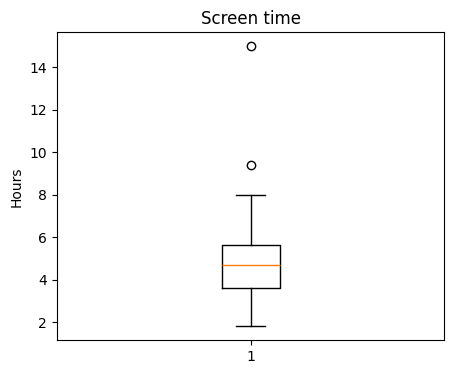

大於 10 小時： 1


In [10]:
# dropna 避免缺失值影響繪圖，資料並未從 df 刪除
plt.figure(figsize=(5, 4))
plt.boxplot(df["screen_time_hours"].dropna())
plt.title("Screen time")
plt.ylabel("Hours")
plt.show()
print("大於 10 小時：", (df["screen_time_hours"] > 10).sum())


## 延伸示範：分箱前後數據不變
相同資料用不同 bins 切分，外觀會不同。學生須檢查各箱人數加總與原本有效筆數是否一致，避免把分箱造成的視覺差異誤認為資料變化。


In [11]:
# numpy 的 histogram 回傳各箱人數及邊界；檢查加總是否一致
valid_scores = df["quiz_score"].dropna()
for bins in [5, 10]:
    counts, edges = np.histogram(valid_scores, bins=bins)
    print("分箱數", bins, "各箱人數", counts, "加總", counts.sum())
    assert counts.sum() == len(valid_scores)


分箱數 5 各箱人數 [ 5  9 20 18  8] 加總 60
分箱數 10 各箱人數 [ 3  2  3  6  9 11 13  5  5  3] 加總 60


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MA｜資料健檢與圖表
**涵蓋：**任務 1～4。這是需要獨立完成、可繳交的整合成果。

### 任務要求
使用 df，以程式列出資料形狀、各欄缺失數、超過 10 小時的筆數；再繪製 quiz_score 直方圖。用文字說明一項品質問題、一項圖表觀察及一項資料限制。不可修改 df。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**df.shape、df.isna()、布林篩選、plt.hist。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 23416 (\N{CJK UNIFIED IDEOGRAPH-5B78}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 25976 (\N{CJK UNIFIED IDEOGRAPH-6578}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  fig.canvas

資料形狀 (列數, 欄數): (10, 3)

各欄位缺失值數量：
student_id     0
screen_time    1
score          1
dtype: int64

螢幕使用時間大於 10 小時的筆數: 4


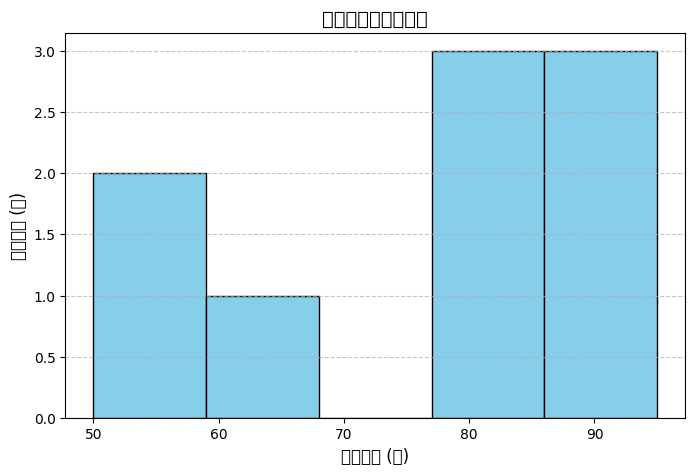

原始 df 是否保持完整未更動: True
納入直方圖的有效筆數: 9


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 設定圖表的中文字型（避免標題或標籤變成亂碼方框）
# Windows 常用 'Microsoft JhengHei'，Mac 常用 'Arial Unicode MS'
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# 1. 建立模擬資料（包含學生編號、每日螢幕時間(小時)、考試成績）
raw_data = {
    'student_id': [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    'screen_time': [8.5, 12.0, 5.0, 14.5, np.nan, 9.0, 11.2, 6.5, 15.0, 7.0],
    'score': [85, 62, 92, 55, 78, 88, np.nan, 95, 50, 81]
}

# 建立原始 DataFrame（後續分析請勿直接更動此變數）
df = pd.DataFrame(raw_data)

# 2. 使用 .copy() 建立獨立的工作複本，保護原始資料
df_clean = df.copy()
# 1. 顯示資料形狀：(列數/總筆數, 欄數/變數數量)
print("資料形狀 (列數, 欄數):", df_clean.shape)

# 2. 顯示各欄位的缺失值（NaN）數量
print("\n各欄位缺失值數量：")
print(df_clean.isnull().sum())

# 3. 計算「螢幕時間大於 10 小時」的筆數
# 邏輯說明：條件判斷會產生 True 與 False，使用 .sum() 時 True 會被當作 1 計算（NaN 會自動視為 False）
screen_over_10 = (df_clean['screen_time'] > 10).sum()
print("\n螢幕使用時間大於 10 小時的筆數:", screen_over_10)
# 取出沒有缺失值的成績欄位
valid_scores = df_clean['score'].dropna()

# 建立畫布與設定尺寸
plt.figure(figsize=(8, 5))

# 繪製直方圖（bins 設定分箱區間數量，edgecolor 加上長條邊框線條）
plt.hist(valid_scores, bins=5, color='skyblue', edgecolor='black')

# 加上標題與座標軸說明
plt.title('學生成績分布直方圖', fontsize=14)
plt.xlabel('成績區間 (分)', fontsize=12)
plt.ylabel('學生人數 (人)', fontsize=12)

# 加上水平虛線網格，方便對照 Y 軸人數
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 顯示圖表
plt.show()
# 驗證程式碼：確認原始 df 與工作複本目前內容一致（未被意外修改）
print("原始 df 是否保持完整未更動:", df.equals(df_clean))

# 驗證程式碼：確認納入直方圖的有效成績筆數
print("納入直方圖的有效筆數:", len(valid_scores))

### ✍️ 小任務 MA｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：＿＿＿＿資料品質與規模健檢：確認資料集的總筆數與欄位數是否符合預期，並盤點各欄位有多少缺失值（空值），避免後續計算出錯
- 實際輸出與至少一項依據數字的觀察：＿＿＿＿有效樣本完整度達 80%（完整紀錄為 8 筆）
從健檢報告可知總資料為 10 筆，雖然 screen_time 與 score 各只有 1 筆缺失值（缺失率各為 10%），但因為這兩筆缺失分別落在不同學生身上（編號 105 缺螢幕時間、編號 107 缺成績），實際上同時具備完整兩項數據的學生共有 8 筆。
- 圖表或模型結果的解讀（依任務要求）：＿＿＿＿樣本涵蓋範圍：本直方圖共納入 9 筆有效成績（已依任務規劃排除編號 107 的 NaN 缺失值），成績全距落在最低 50 分至最高 95 分之間。
- 資料品質、模擬資料或評估限制：＿＿＿＿缺失值造成的樣本耗損：

總樣本數僅 10 筆，其中 screen_time（編號 105）與 score（編號 107）各有 1 筆缺失值（NaN）。

雖然單一欄位的缺失率為 10%，但因為缺失發生在不同學生身上，導致若要進行雙變數完整分析，可用樣本會縮減為 8 筆（耗損 20%）。此外，在篩選 screen_time > 10 時，缺失值被預設判定為 False，若該名學生實際使用超過 10 小時，將會造成計數低估。
- 驗證方法與結果：＿＿＿＿原始資料完整性比對（Data Integrity Check）

方法：在建立工作複本 df_clean = df.copy() 並完成健檢後，使用 df.equals(df_clean) 比對兩者的結構與數值是否完全一致，確認分析過程未意外修改原始 df。
- AI 工具、實際提示詞、人工修改與遇到的問題：＿＿＿＿程式碼複製截斷導致語法錯誤
- 重新執行是否成功及環境或檔案需求：＿＿＿＿是
